# BRB-seq expression QC and PCA

This notebook compares deep non-UMI gene counts with deep UMI-deduplicated counts, maps barcodes to sample IDs, applies DESeq2's variance-stabilizing transform to the UMI counts, and makes separate gill and liver PCA plots. No differential-expression model is fitted here.

The compiled sample metadata are used for labels and annotations. `2024_DJR_196` is intentionally retained with unknown sex so its position can be inspected in the gill PCA.

In [1]:
library(DESeq2)
library(Matrix)
library(ggplot2)

# Edit these paths only if the repository/output location changes.
repo_root <- "/scratch/ztobias/Gacu_BC_txmics"
star_root <- file.path(repo_root, "outputs", "star")
metadata_file <- file.path(repo_root, "metadata", "derived", "sample_tracking.tsv")
barcode_file <- file.path(repo_root, "metadata", "brb_sample_barcodes.tsv")

tracking <- read.delim(metadata_file, header = TRUE, sep = "\t",
  stringsAsFactors = FALSE, check.names = FALSE)
brb_barcodes <- read.delim(barcode_file, header = TRUE, sep = "\t",
  stringsAsFactors = FALSE, check.names = FALSE)

tracking <- tracking[grepl("^(2024|2025)_DJR_", tracking$sample_id), ]
brb_barcodes <- brb_barcodes[grepl("^(2024|2025)_DJR_", brb_barcodes$sample_id), ]
tracking$ecotype <- tolower(trimws(tracking$ecotype))
tracking$site_type <- tolower(trimws(tracking$site_type))
tracking$ecotype_plot <- tracking$ecotype
is_2025 <- tracking$year == 2025
tracking$ecotype_plot[is_2025 & tracking$site_type == "lake"] <- "lake"
tracking$ecotype_plot[is_2025 & tracking$site_type %in% c("stream", "mouth", "upstream")] <- "stream"
tracking$ecotype_plot[!is_2025 & tracking$ecotype_plot == "freshwater"] <- "lake"
allowed_ecotypes <- c("lake", "stream", "marine", "benthic", "limnetic")
tracking$ecotype_plot[!tracking$ecotype_plot %in% allowed_ecotypes] <- NA_character_
head(tracking[, c("sample_id", "population", "ecotype", "field_sex", "true_sex")])

Loading required package: S4Vectors

Warning message:
“package ‘S4Vectors’ was built under R version 4.1.3”
Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, append, as.data.frame, basename, cbind, colnames,
    dirname, do.call, duplicated, eval, evalq, Filter, Find, get, grep,
    grepl, intersect, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, setdiff, sort, table, tapply,
    union, unique, unsplit, which.max, which.min



Attaching package: ‘S4Vectors’


The following objects are masked from ‘package:base’:

    expand.grid, I, unname


Loading required package: IRanges

Warning message:
“package ‘IRanges’ was built under R version 4.1.3”
Loading required packag

,sample_id,population,ecotype,field_sex,true_sex
,<chr>,<chr>,<chr>,<chr>,<chr>
1,2024_DJR_001,Priest,limnetic,M,M
2,2024_DJR_002,Priest,limnetic,F,F
3,2024_DJR_003,Priest,benthic,F,F
4,2024_DJR_004,Priest,limnetic,M,M
5,2024_DJR_005,Priest,limnetic,F,F
6,2024_DJR_006,Priest,benthic,M,M


## Read and map STAR's deep gene-count and UMI-count matrices

Each year/tissue run has its own STARsolo matrix. The 2025 gill and liver matrices already represent the independent tissue run plus the combined lane, because those FASTQs were concatenated before STAR. STAR was run with `NoDedup 1MM_Directional`, so the two matrices are `umiDedup-NoDedup.mtx` and `umiDedup-1MM_Directional.mtx`.

In [2]:
read_star_matrix <- function(matrix_path) {
  if (!file.exists(matrix_path)) stop("Missing STAR matrix: ", matrix_path)
  raw_dir <- dirname(matrix_path)
  barcode_path <- file.path(raw_dir, "barcodes.tsv")
  feature_path <- file.path(raw_dir, "features.tsv")
  x <- as.matrix(readMM(matrix_path))
  features <- read.delim(feature_path, header = FALSE, sep = "\t",
    stringsAsFactors = FALSE, check.names = FALSE)
  barcodes <- readLines(barcode_path)
  rownames(x) <- make.unique(features[[1]])
  colnames(x) <- barcodes
  storage.mode(x) <- "numeric"
  x
}

matrix_file <- function(tissue, year, mode = c("gene", "umi")) {
  mode <- match.arg(mode)
  prefix <- file.path(star_root, paste0(tissue, "_", year, "_deep_Solo.out"), "Gene", "raw")
  file.path(prefix, if (mode == "gene") "umiDedup-NoDedup.mtx" else "umiDedup-1MM_Directional.mtx")
}

map_matrix_to_samples <- function(x, tissue, year) {
  map <- brb_barcodes[brb_barcodes$tissue == tissue &
    brb_barcodes$year == as.integer(year), c("sample_id", "barcode")]
  map <- map[!duplicated(map$barcode), ]
  sample_names <- map$sample_id[match(colnames(x), map$barcode)]
  if (anyNA(sample_names)) {
    cat("Unmapped barcodes for ", tissue, " ", year, ":\n")
    print(colnames(x)[is.na(sample_names)])
  }
  keep <- !is.na(sample_names)
  x <- x[, keep, drop = FALSE]
  colnames(x) <- sample_names[keep]
  x
}

read_tissue_counts <- function(tissue, mode = c("gene", "umi")) {
  mode <- match.arg(mode)
  mats <- lapply(c("2024", "2025"), function(year) {
    x <- read_star_matrix(matrix_file(tissue, year, mode))
    map_matrix_to_samples(x, tissue, year)
  })
  genes <- Reduce(intersect, lapply(mats, rownames))
  mats <- lapply(mats, function(x) x[genes, , drop = FALSE])
  out <- do.call(cbind, mats)
  if (anyDuplicated(colnames(out))) stop("Duplicate sample IDs in ", tissue, " matrix")
  out
}

gill_gene_counts <- read_tissue_counts("gill", "gene")
liver_gene_counts <- read_tissue_counts("liver", "gene")
gill_umi_counts <- read_tissue_counts("gill", "umi")
liver_umi_counts <- read_tissue_counts("liver", "umi")

# The gene and UMI matrices should contain the same sample and gene sets.
stopifnot(identical(dim(gill_gene_counts), dim(gill_umi_counts)))
stopifnot(identical(dim(liver_gene_counts), dim(liver_umi_counts)))
dim(gill_gene_counts)
dim(liver_gene_counts)

Unmapped barcodes for  gill   2024 :
[1] "ACGATGCGACTACG" "ACTTAACCATACCA" "CCGCAATATGGCAA" "CTACTCAGTGTCGC"
[5] "CTATGCTAGCGAGC" "TATGCCATGCCTAC" "TCGACTGCATGCGA" "TCTTACAGCCAGCC"
[9] "TTACATCTAGTCCA"
Unmapped barcodes for  gill   2025 :
  [1] "AACAACCGCTAACC" "AACAACCTTCCAAG" "AACAACGCCGGCCA" "AACAACTCGCACGG"
  [5] "AACAAGGTGTCCAA" "AACCAGAGAATGGC" "AACCGTGACATTAC" "AACCTGAGGCAAGA"
  [9] "AACGGTACTGAAGA" "AACGTTAAGTCCGA" "AAGAACGGCCTGGC" "AAGCATTCTGGCCG"
 [13] "AAGCCGCACACAAG" "AAGCCGTGATTCCG" "AAGGAAGTGCGCCA" "AAGGCGCTTCAACG"
 [17] "AAGTGAATACCAAC" "AATCCTGGTACACG" "AATGCCTTGTAAGG" "AATGGAACCGTGAG"
 [21] "AATTATACCGCTCA" "ACAATACCGCCAAG" "ACACACGAGCAGCG" "ACACATATGACAGC"
 [25] "ACACGACAGCTCAC" "ACACTACTCGTGCA" "ACAGATGCGTGCGC" "ACAGCAGTATAGCA"
 [29] "ACAGCTGCTGTACA" "ACATAGTCATCTGA" "ACATGGAGGAGAAC" "ACCGGCCAATAACA"
 [33] "ACGATGCTCATCAC" "ACGGTTCAACATAA" "ACGTACTAGAGCGA" "ACGTCAGCATCGAC"
 [37] "ACTAGACGCACACA" "ACTCATGATGCTGA" "ACTCCATATTCGGC" "ACTCTGCGCTCGAC"
 [41] "ACTGAGTCTAGAGA

[1] 28136   630

[1] 28136   639

In [3]:
make_coldata <- function(counts) {
  md <- tracking[match(colnames(counts), tracking$sample_id), , drop = FALSE]
  if (anyNA(md$sample_id)) stop("Count matrix sample missing from compiled metadata")
  rownames(md) <- md$sample_id
  md
}

gill_metadata <- make_coldata(gill_gene_counts)
liver_metadata <- make_coldata(liver_gene_counts)

# Unknown sex is retained as NA. Do not replace it before inspecting PCA.
gill_metadata[gill_metadata$sample_id == "2024_DJR_196",
  c("sample_id", "field_sex", "true_sex", "population", "ecotype")]

table(gill_metadata$year, useNA = "ifany")
table(liver_metadata$year, useNA = "ifany")

,sample_id,field_sex,true_sex,population,ecotype
,<chr>,<chr>,<chr>,<chr>,<chr>
2024_DJR_196,2024_DJR_196,?,,Boot,lake



2024 2025 
 375  255 


2024 2025 
 375  264 

## Gene-count versus UMI-count comparison

First compare total counts retained after UMI deduplication. A lower UMI/gene ratio indicates more PCR duplication. The population summaries are descriptive only; they show whether deduplication affects populations differently before choosing the expression matrix for PCA.

In [4]:
# Inspect the matrices before giving them to DESeq2.
count_diagnostics <- function(counts, label) {
  cat("\n--- ", label, " ---\n")
  cat("dimensions: ", nrow(counts), " genes x ", ncol(counts), " samples\n")
  cat("NA values: ", sum(is.na(counts)), "\n")
  cat("negative values: ", sum(counts < 0, na.rm = TRUE), "\n")
  cat("all-zero genes: ", sum(rowSums(counts) == 0), "\n")
  cat("all-zero samples: ", sum(colSums(counts) == 0), "\n")
  sample_summary <- data.frame(
    sample = colnames(counts),
    total_counts = colSums(counts),
    detected_genes = colSums(counts > 0),
    zero_genes = colSums(counts == 0)
  )
  print(summary(sample_summary$total_counts))
  print(summary(sample_summary$detected_genes))
  print(sample_summary[order(sample_summary$total_counts), ])
  invisible(sample_summary)
}

gill_gene_diagnostics <- count_diagnostics(gill_gene_counts, "gill gene")
liver_gene_diagnostics <- count_diagnostics(liver_gene_counts, "liver gene")
gill_umi_diagnostics <- count_diagnostics(gill_umi_counts, "gill UMI")
liver_umi_diagnostics <- count_diagnostics(liver_umi_counts, "liver UMI")


---  gill gene  ---
dimensions:  28136  genes x  630  samples
NA values:  0 
negative values:  0 
all-zero genes:  3806 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 223225 2589599 2852239 2812055 3072113 6129952 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  12225   15740   16216   16569   17658   19616 
                   sample total_counts detected_genes zero_genes
2025_DJR_267 2025_DJR_267       223225          12225      15911
2025_DJR_286 2025_DJR_286       360418          13589      14547
2025_DJR_254 2025_DJR_254       497571          14586      13550
2025_DJR_263 2025_DJR_263       517747          14410      13726
2025_DJR_266 2025_DJR_266       522012          13857      14279
2025_DJR_276 2025_DJR_276       672652          15605      12531
2025_DJR_052 2025_DJR_052       988416          16137      11999
2025_DJR_018 2025_DJR_018      1088971          16158      11978
2025_DJR_265 2025_DJR_265      1116783          15984      12152
2024_DJR_1


---  liver gene  ---
dimensions:  28136  genes x  639  samples
NA values:  0 
negative values:  0 
all-zero genes:  4139 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 115176 1813222 1992323 2167730 2607216 7050734 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   6103   12161   12703   12654   13260   16753 
                   sample total_counts detected_genes zero_genes
2024_DJR_104 2024_DJR_104       115176           6103      22033
2024_DJR_203 2024_DJR_203       128712           6305      21831
2024_DJR_094 2024_DJR_094       310024           7751      20385
2024_DJR_039 2024_DJR_039       383977           7966      20170
2024_DJR_105 2024_DJR_105       397768           9643      18493
2024_DJR_295 2024_DJR_295       505020          10724      17412
2024_DJR_085 2024_DJR_085       614961           9812      18324
2024_DJR_097 2024_DJR_097       649092          10668      17468
2024_DJR_009 2024_DJR_009       694703           9070      19066
2024_DJR_


---  gill UMI  ---
dimensions:  28136  genes x  630  samples
NA values:  0 
negative values:  0 
all-zero genes:  3806 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 154412  801226  918180 1215448 1766757 4227987 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  12225   15740   16216   16569   17658   19616 
                   sample total_counts detected_genes zero_genes
2025_DJR_267 2025_DJR_267       154412          12225      15911
2025_DJR_286 2025_DJR_286       257644          13589      14547
2025_DJR_254 2025_DJR_254       358284          14586      13550
2025_DJR_266 2025_DJR_266       359173          13857      14279
2025_DJR_263 2025_DJR_263       366493          14410      13726
2024_DJR_121 2024_DJR_121       432956          15012      13124
2024_DJR_287 2024_DJR_287       462964          15118      13018
2024_DJR_288 2024_DJR_288       463657          15468      12668
2025_DJR_276 2025_DJR_276       487341          15605      12531
2024_DJR_19


---  liver UMI  ---
dimensions:  28136  genes x  639  samples
NA values:  0 
negative values:  0 
all-zero genes:  4139 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  59729  988956 1142873 1088587 1226782 3103504 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   6103   12161   12703   12654   13260   16753 
                   sample total_counts detected_genes zero_genes
2024_DJR_104 2024_DJR_104        59729           6103      22033
2024_DJR_203 2024_DJR_203        63574           6305      21831
2024_DJR_094 2024_DJR_094       140468           7751      20385
2024_DJR_039 2024_DJR_039       175916           7966      20170
2024_DJR_105 2024_DJR_105       204832           9643      18493
2024_DJR_295 2024_DJR_295       256886          10724      17412
2024_DJR_085 2024_DJR_085       291846           9812      18324
2024_DJR_009 2024_DJR_009       299195           9070      19066
2024_DJR_097 2024_DJR_097       310168          10668      17468
2024_DJR_4

In [5]:
summarize_count_ratio <- function(gene_counts, umi_counts, metadata, tissue) {
  stopifnot(identical(rownames(gene_counts), rownames(umi_counts)))
  stopifnot(identical(colnames(gene_counts), colnames(umi_counts)))
  sample_metadata <- metadata[match(colnames(gene_counts), metadata$sample_id), , drop = FALSE]
  total_gene <- colSums(gene_counts)
  total_umi <- colSums(umi_counts)
  data.frame(
    sample_id = colnames(gene_counts),
    tissue = tissue,
    year = sample_metadata$year,
    population = sample_metadata$population,
    ecotype = sample_metadata$ecotype_plot,
    gene_counts = total_gene,
    umi_counts = total_umi,
    umi_to_gene_ratio = ifelse(total_gene > 0, total_umi / total_gene, NA_real_),
    stringsAsFactors = FALSE
  )
}

count_ratio_by_sample <- rbind(
  summarize_count_ratio(gill_gene_counts, gill_umi_counts, gill_metadata, "gill"),
  summarize_count_ratio(liver_gene_counts, liver_umi_counts, liver_metadata, "liver")
)

grouped <- split(seq_len(nrow(count_ratio_by_sample)),
  interaction(count_ratio_by_sample$tissue, count_ratio_by_sample$population,
    count_ratio_by_sample$ecotype, drop = TRUE))
count_ratio_by_population <- do.call(rbind, lapply(grouped, function(i) {
  x <- count_ratio_by_sample$umi_to_gene_ratio[i]
  data.frame(
    tissue = count_ratio_by_sample$tissue[i[1]],
    population = count_ratio_by_sample$population[i[1]],
    ecotype = count_ratio_by_sample$ecotype[i[1]],
    n = sum(!is.na(x)),
    median_umi_to_gene = median(x, na.rm = TRUE),
    mean_umi_to_gene = mean(x, na.rm = TRUE),
    sd_umi_to_gene = sd(x, na.rm = TRUE),
    stringsAsFactors = FALSE
  )
}))
row.names(count_ratio_by_population) <- NULL
count_ratio_by_sample[order(count_ratio_by_sample$tissue, count_ratio_by_sample$umi_to_gene_ratio), ]
count_ratio_by_population[order(count_ratio_by_population$tissue, count_ratio_by_population$population), ]

ratio_plot <- ggplot(count_ratio_by_sample, aes(x = population, y = umi_to_gene_ratio)) +
  geom_boxplot(outlier.size = 0.6, na.rm = TRUE) +
  facet_wrap(~ tissue, scales = "free_x") +
  coord_cartesian(ylim = c(0, 1)) +
  labs(title = "UMI counts retained relative to gene counts",
    x = "Population", y = "UMI counts / non-UMI gene counts") +
  theme_classic() +
  theme(axis.text.x = element_text(angle = 60, hjust = 1))
dir.create(file.path(repo_root, "vis"), showWarnings = FALSE)
ggsave(file.path(repo_root, "vis", "BRBseq_UMI_gene_count_ratio.png"),
  ratio_plot, width = 16, height = 10, units = "in", dpi = 300)

# Use UMI-deduplicated counts for the exploratory expression PCA.
make_vsd <- function(counts, metadata) {
  keep <- rowSums(counts >= 10) >= max(2, ceiling(ncol(counts) * 0.10))
  dds <- DESeqDataSetFromMatrix(
    countData = round(counts[keep, , drop = FALSE]),
    colData = metadata,
    design = ~ 1
  )
  list(
    dds = dds,
    vsd = vst(dds, blind = TRUE),
    genes_kept = sum(keep)
  )
}

gill_vsd <- make_vsd(gill_umi_counts, gill_metadata)
liver_vsd <- make_vsd(liver_umi_counts, liver_metadata)
c(gill = gill_vsd$genes_kept, liver = liver_vsd$genes_kept)

,sample_id,tissue,year,population,ecotype,gene_counts,umi_counts,umi_to_gene_ratio
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
2024_DJR_311,2024_DJR_311,gill,2024,Merrill,lake,3947873,997713,0.2527217
2024_DJR_344,2024_DJR_344,gill,2024,McCreight,lake,3367289,856078,0.2542336
2024_DJR_087,2024_DJR_087,gill,2024,Paxton,benthic,3012481,774037,0.2569434
2024_DJR_212,2024_DJR_212,gill,2024,Boot,lake,3446588,886866,0.2573171
2024_DJR_307,2024_DJR_307,gill,2024,Merrill,lake,2880341,741826,0.2575480
2024_DJR_105,2024_DJR_105,gill,2024,Little Quarry,benthic,3146960,810625,0.2575899
2024_DJR_018,2024_DJR_018,gill,2024,Priest,benthic,3443128,890675,0.2586819
2024_DJR_298,2024_DJR_298,gill,2024,Merrill,lake,2783974,720694,0.2588724
2024_DJR_013,2024_DJR_013,gill,2024,Priest,benthic,3878065,1004251,0.2589567


,tissue,population,ecotype,n,median_umi_to_gene,mean_umi_to_gene,sd_umi_to_gene
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
7,gill,Amor,lake,13,0.2755586,0.2813032,0.020110531
9,gill,Beaver,lake,20,0.6880242,0.6887776,0.009475112
55,gill,Beaver,stream,20,0.6917748,0.6936030,0.007584417
49,gill,Black Creek,marine,20,0.2727917,0.2756156,0.010314477
11,gill,Bob,lake,20,0.2757581,0.2794608,0.016285795
13,gill,Boot,lake,19,0.2750917,0.2753237,0.009203842
51,gill,Campbell River,marine,11,0.2762661,0.2781985,0.007811699
15,gill,Comida,lake,20,0.6914572,0.6927538,0.008781220
57,gill,Comida,stream,20,0.6928814,0.6924369,0.009059660


converting counts to integer mode

converting counts to integer mode

-- note: fitType='parametric', but the dispersion trend was not well captured by the
   function: y = a/x + b, and a local regression fit was automatically substituted.
   specify fitType='local' or 'mean' to avoid this message next time.



gill liver 
13378  7943

Okay wow so there is a lot of duplication in the 2024 populations. Differences among tissues too. Definitely should use UMI counts then.

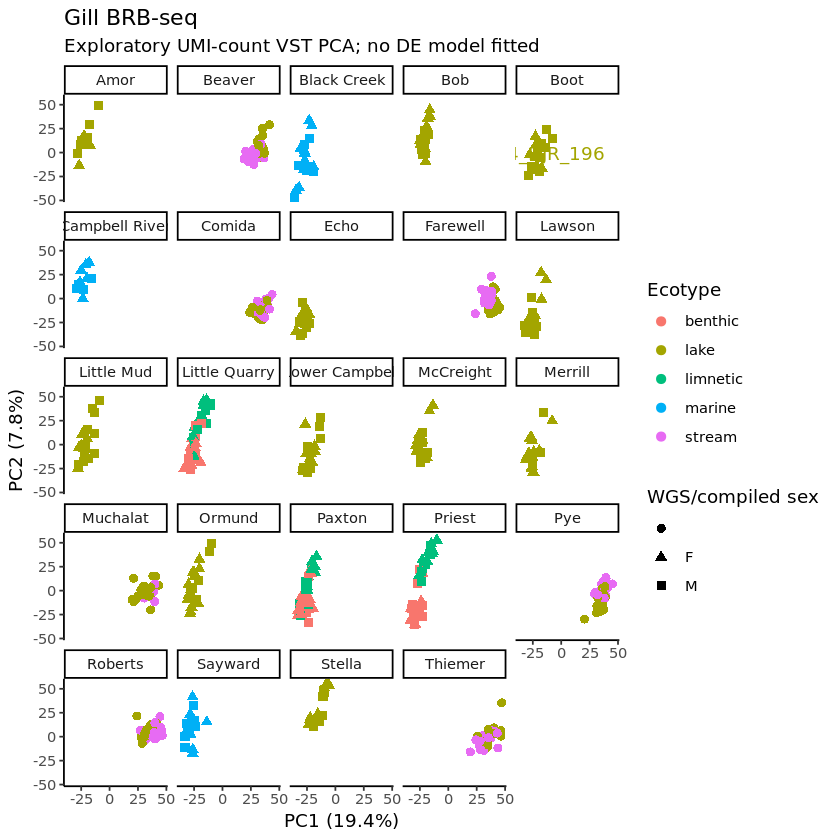

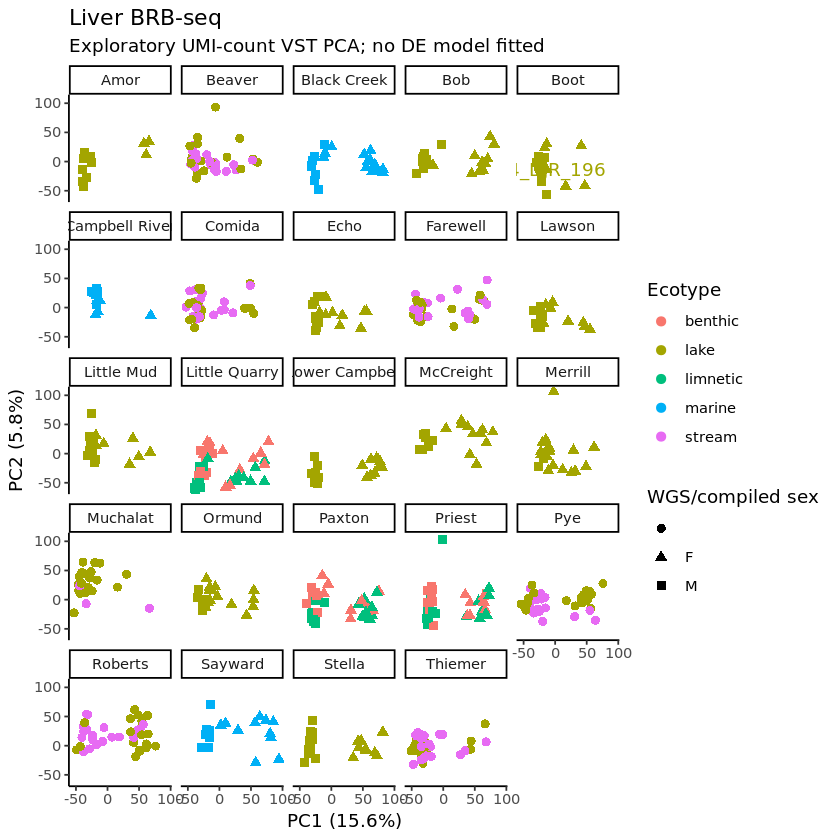

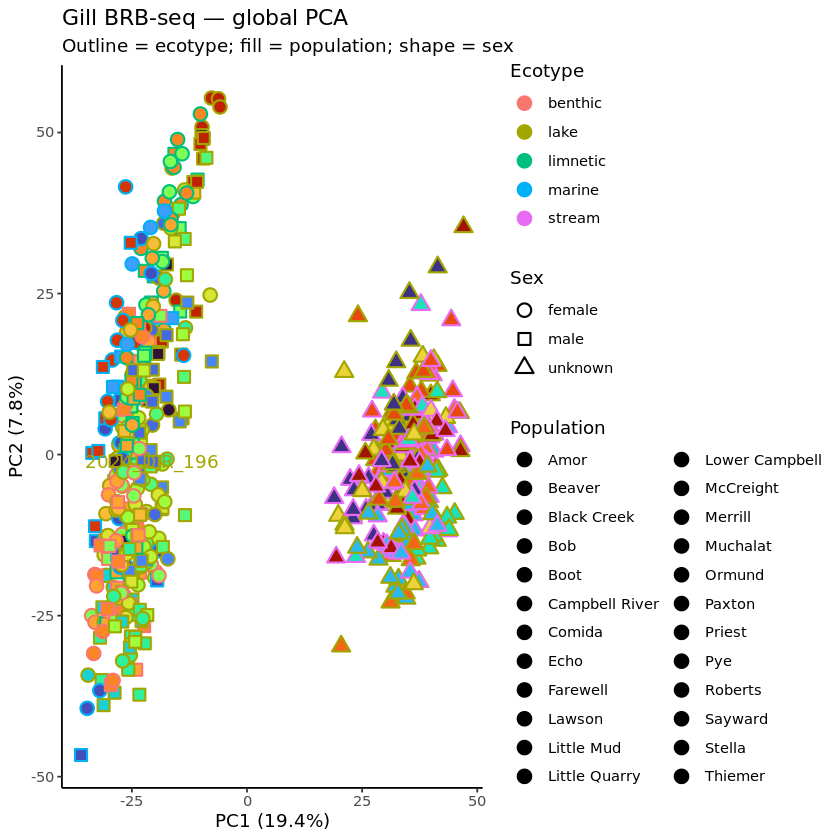

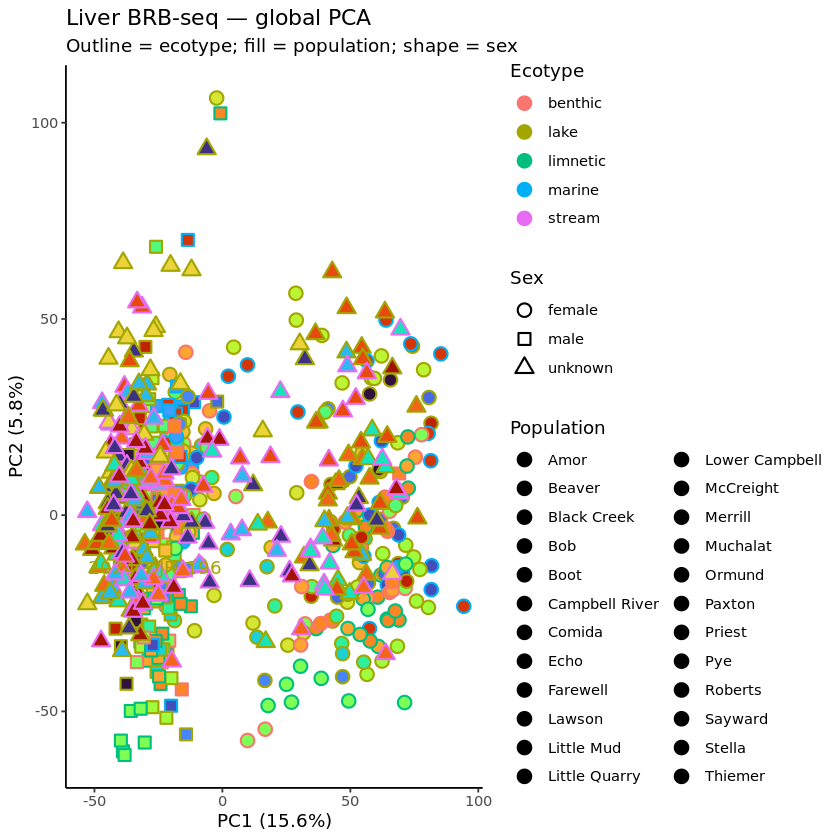

In [6]:
make_pca_data <- function(vsd_obj, metadata) {
  pca <- prcomp(t(assay(vsd_obj)), center = TRUE, scale. = FALSE)
  variance <- 100 * pca$sdev^2 / sum(pca$sdev^2)
  out <- cbind(metadata,
    PC1 = pca$x[, 1], PC2 = pca$x[, 2])
  attr(out, "variance") <- variance
  out
}

gill_pca_data <- make_pca_data(gill_vsd$vsd, gill_metadata)
liver_pca_data <- make_pca_data(liver_vsd$vsd, liver_metadata)

plot_pca <- function(pca_data, title) {
  variance <- attr(pca_data, "variance")
  ggplot(pca_data, aes(PC1, PC2, color = ecotype_plot, shape = true_sex)) +
    geom_point(size = 2.2, na.rm = FALSE) +
    geom_text(
      data = pca_data[pca_data$sample_id == "2024_DJR_196", , drop = FALSE],
      aes(label = sample_id), nudge_y = 0.02, na.rm = TRUE, show.legend = FALSE
    ) +
    facet_wrap(~ population) +
    labs(
      title = title,
      subtitle = "Exploratory UMI-count VST PCA; no DE model fitted",
      x = paste0("PC1 (", round(variance[1], 1), "%)"),
      y = paste0("PC2 (", round(variance[2], 1), "%)"),
      color = "Ecotype",
      shape = "WGS/compiled sex"
    ) +
    theme_classic()
}

gill_pca_plot <- plot_pca(gill_pca_data, "Gill BRB-seq")
liver_pca_plot <- plot_pca(liver_pca_data, "Liver BRB-seq")
gill_pca_plot
liver_pca_plot
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA.png"),
  gill_pca_plot, width = 18, height = 14, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA.png"),
  liver_pca_plot, width = 18, height = 14, units = "in", dpi = 300)

# Global PCA: outline color = ecotype, fill = population, shape = sex.
# Filled point shapes keep all three annotations visible at once.
plot_pca_global <- function(pca_data, title) {
  variance <- attr(pca_data, "variance")
  sex <- tolower(trimws(pca_data$true_sex))
  pca_data$sex_plot <- ifelse(sex %in% c("m", "male"), "male",
    ifelse(sex %in% c("f", "female"), "female", "unknown"))
  ggplot(pca_data, aes(PC1, PC2, color = ecotype_plot, fill = population,
    shape = sex_plot)) +
    geom_point(size = 3.2, stroke = 0.9, na.rm = FALSE) +
    geom_text(
      data = pca_data[pca_data$sample_id == "2024_DJR_196", , drop = FALSE],
      aes(label = sample_id), nudge_y = 0.02, na.rm = TRUE,
      show.legend = FALSE
    ) +
    scale_shape_manual(values = c(female = 21, male = 22, unknown = 24)) +
    scale_fill_viridis_d(option = "turbo", end = 0.95) +
    labs(
      title = paste0(title, " — global PCA"),
      subtitle = "Outline = ecotype; fill = population; shape = sex",
      x = paste0("PC1 (", round(variance[1], 1), "%)"),
      y = paste0("PC2 (", round(variance[2], 1), "%)"),
      color = "Ecotype", fill = "Population", shape = "Sex"
    ) +
    guides(
      color = guide_legend(order = 1),
      shape = guide_legend(order = 2),
      fill = guide_legend(order = 3, ncol = 2)
    ) +
    theme_classic() +
    theme(legend.position = "right")
}

gill_global_pca <- plot_pca_global(gill_pca_data, "Gill BRB-seq")
liver_global_pca <- plot_pca_global(liver_pca_data, "Liver BRB-seq")
gill_global_pca
liver_global_pca
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA_global.png"),
  gill_global_pca, width = 22, height = 16, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA_global.png"),
  liver_global_pca, width = 22, height = 16, units = "in", dpi = 300)

### Interpretation note

If `2024_DJR_196` clusters clearly with one sex in the gill PCA, that is useful evidence for follow-up, but it is not by itself a genetic-sex assignment. Population, ecotype, batch, sequencing depth, and sample-quality structure can also drive PCA separation.